In [1]:
%pylab inline
import pandas as pd

Populating the interactive namespace from numpy and matplotlib


In [2]:
from glob import glob

In [3]:
big = pd.concat(pd.read_csv(fname) for fname in glob('data/rep6/rep6-*.csv'))

In [4]:
big.shape

(53520485, 5)

In [5]:
import scipy.io

In [6]:
cellBoundaries = scipy.io.loadmat('data/rep6/cellBoundaries.mat')

In [7]:
cellBoundaries['cellBoundaries'][0][12][-3][0, 0], \
cellBoundaries['cellBoundaries'][0][12][-2][0, 0], \
cellBoundaries['cellBoundaries'][0][12][-1][0, 0]

(166.75416576000003, 890.7706080000002, 13)

In [8]:
big_sample_info = pd.DataFrame(np.zeros((cellBoundaries['cellBoundaries'][0].shape[0], 3)),
                               columns=['nucleusArea', 'cytoplasmArea', 'cellID'])

for i in big_sample_info.index:
    row = \
    cellBoundaries['cellBoundaries'][0][i][-3][0, 0], \
    cellBoundaries['cellBoundaries'][0][i][-2][0, 0], \
    cellBoundaries['cellBoundaries'][0][i][-1][0, 0]
    
    big_sample_info.loc[i, :] = row
    
big_sample_info.cellID = big_sample_info.cellID.astype(int64)
big_sample_info = big_sample_info.set_index('cellID')

In [9]:
middle = big.query('-450 < abs_X < 600 & -450 < abs_Y < 600')

In [10]:
middle.cellID.unique().shape

(1123,)

In [11]:
codebook = pd.read_csv('data/codebook.csv', skiprows=3)

In [12]:
codebook['barcode_id'] = codebook.index + 1

In [13]:
codebook.head()

,name,id,barcode,barcode_id
0,Blank-1,,11100000001000,1
1,Blank-10,,1001100100000000,2
2,Blank-2,,11000100100000,3
3,Blank-3,,11010001000000,4
4,Blank-4,,10010000001100,5


In [14]:
middle = middle.merge(codebook[['name', 'barcode_id']], on='barcode_id')

In [19]:
big = big.merge(codebook[['name', 'barcode_id']], on='barcode_id')

In [20]:
big.head()

,barcode,barcode_id,abs_X,abs_Y,cellID,name
0,4124,1,-2588.5,-4004.5,3,Blank-1
1,4124,1,-2584.1,-4014.6,8,Blank-1
2,4124,1,-2583.4,-4000.1,3,Blank-1
3,4124,1,-2578.5,-3963.6,4,Blank-1
4,4124,1,-2577.9,-4087.7,6,Blank-1


In [22]:
big_sample_info.head()

,nucleusArea,cytoplasmArea
cellID,,
1,188.886298,777.677322
2,198.330612,877.844298
3,171.142433,602.671306
4,178.440313,714.667524
5,194.657823,215.740587


In [21]:
middle.head()

,barcode,barcode_id,abs_X,abs_Y,cellID,name
0,4124,1,1.7591,529.75,19632,Blank-1
1,4124,1,6.9139,573.57,20938,Blank-1
2,4124,1,11.3920,554.25,20938,Blank-1
3,4124,1,14.5480,570.84,20938,Blank-1
4,4124,1,15.6350,523.21,20937,Blank-1


Make huge picture of all data

In [15]:
N = 1000

X_intervals, X_bins = pd.cut( big['abs_X'].unique(), N, retbins=True)
Y_intervals, Y_bins = pd.cut( big['abs_Y'].unique(), N, retbins=True)

In [16]:
xx = np.array([-450, -450, 600, 600, -450])
yy = np.array([-450, 600, 600, -450, -450])

In [17]:
xx_img = np.less.outer(X_bins, xx).sum(0) * (N / (N + 1))
yy_img = np.less.outer(Y_bins, yy).sum(0) * (N / (N + 1))

In [18]:
tmp = big

grid_counts = tmp.groupby( [pd.cut( tmp['abs_X'], N), pd.cut( tmp['abs_Y'], N)] ).count()['abs_X'].to_frame()
img_mat = grid_counts.unstack().replace(np.nan, 0)

In [19]:
codebook.query('name == "MALAT1"')

,name,id,barcode,barcode_id
127,MALAT1,ENST00000534336.1,100000000010101,128


In [20]:
tmp = big.query('barcode_id == 128')

In [21]:
grid_counts = tmp.groupby( [pd.cut( tmp['abs_X'], N), pd.cut( tmp['abs_Y'], N)] ).count()['abs_X'].to_frame()
img_mat_malat = grid_counts.unstack().replace(np.nan, 0)

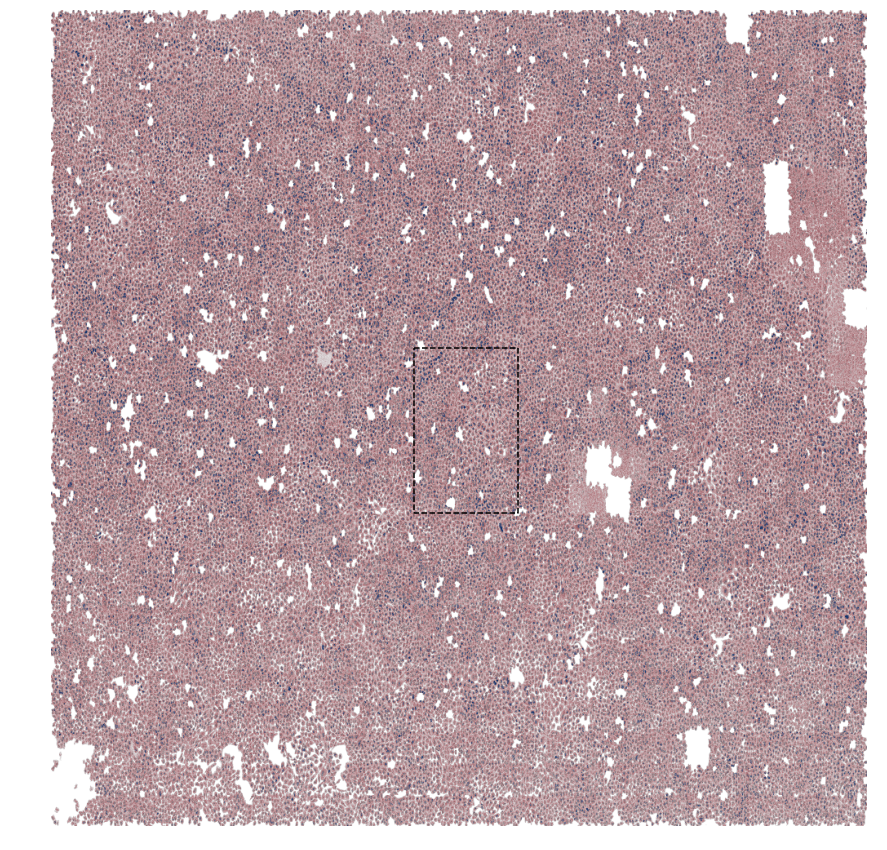

In [22]:
figsize(15, 15)
final_img = cm.Purples(img_mat / img_mat.max())
final_img[:, :, :] = cm.Reds(255)
final_img[:, :, 3] = img_mat / img_mat.max() * 0.66

tmp_img = cm.Blues(img_mat_malat / img_mat_malat.max())
tmp_img[:, :, :] = cm.Blues(255)
tmp_img[:, :, 3] = img_mat_malat / img_mat_malat.max()

plt.imshow(final_img, interpolation='hermite');
plt.imshow(tmp_img, interpolation='hermite');
plt.axis('equal');
plt.axis('off');

plt.plot(yy_img, xx_img, ls='--', c='k');
plt.savefig('big_picture.jpg')

Make zoomed in image

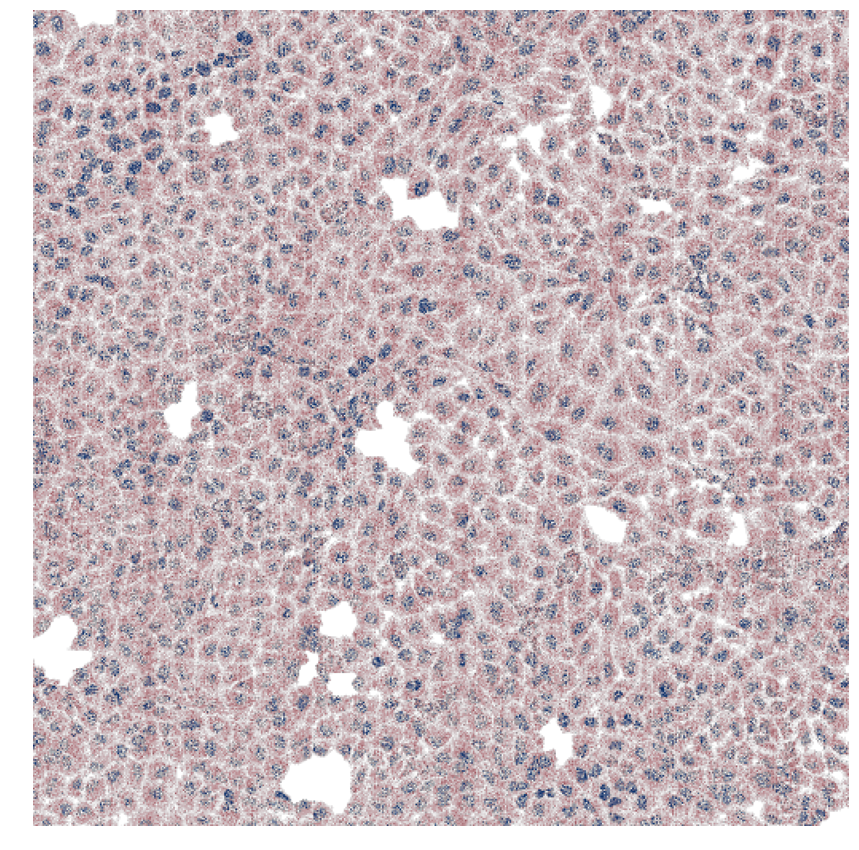

In [23]:
N = 512

tmp = middle


grid_counts = tmp.groupby( [pd.cut( tmp['abs_X'], N), pd.cut( tmp['abs_Y'], N)] ).count()['abs_X'].to_frame()
img_mat = grid_counts.unstack().replace(np.nan, 0)

final_img = cm.Purples(img_mat / img_mat.max())
final_img[:, :, :] = cm.Reds(255)
final_img[:, :, 3] = img_mat / img_mat.max() * 0.66

tmp = middle.query('name == "MALAT1"')

grid_counts = tmp.groupby( [pd.cut( tmp['abs_X'], N), pd.cut( tmp['abs_Y'], N)] ).count()['abs_X'].to_frame()
img_mat = grid_counts.unstack().replace(np.nan, 0)

tmp_img = cm.Blues(img_mat / img_mat.max())
tmp_img[:, :, :] = cm.Blues(255)
tmp_img[:, :, 3] = img_mat / img_mat.max()
# final_img += tmp_img

plt.imshow(final_img, interpolation='hermite');
plt.imshow(tmp_img, interpolation='hermite')
plt.axis('off');

plt.savefig('middle_picture.jpg')

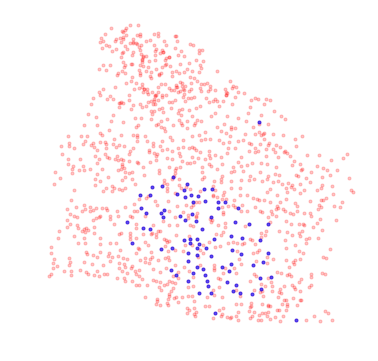

In [24]:
sample_cell = middle.cellID.sample().iloc[0]
a_cell = middle.query('cellID == {}'.format(sample_cell))

figsize(6, 6)
plt.scatter(a_cell.abs_X, a_cell.abs_Y, alpha=0.22, c='red', marker='.');
a_nucleus = a_cell.query('name == "MALAT1"')
plt.scatter(a_nucleus.abs_X, a_nucleus.abs_Y, alpha=0.6, c='blue', marker='.');
plt.axis('off');

In [25]:
sample_info = \
middle.groupby(['cellID']) \
    .mean()[['abs_X', 'abs_Y']]

In [26]:
sample_info = sample_info.join(big_sample_info)

In [27]:
X_intervals, X_bins = pd.cut( middle['abs_X'].unique(), N, retbins=True)
Y_intervals, Y_bins = pd.cut( middle['abs_Y'].unique(), N, retbins=True)

In [28]:
xx_img = np.less.outer(X_bins, sample_info.abs_X).sum(0) * (N / (N + 1))
yy_img = np.less.outer(Y_bins, sample_info.abs_Y).sum(0) * (N / (N + 1))

In [29]:
np.less.outer(X_bins, sample_info.abs_X)

array([[ True,  True,  True, ...,  True,  True,  True],
       [False,  True,  True, ...,  True,  True,  True],
       [False, False,  True, ...,  True,  True,  True],
       ..., 
       [False, False, False, ..., False,  True,  True],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]], dtype=bool)

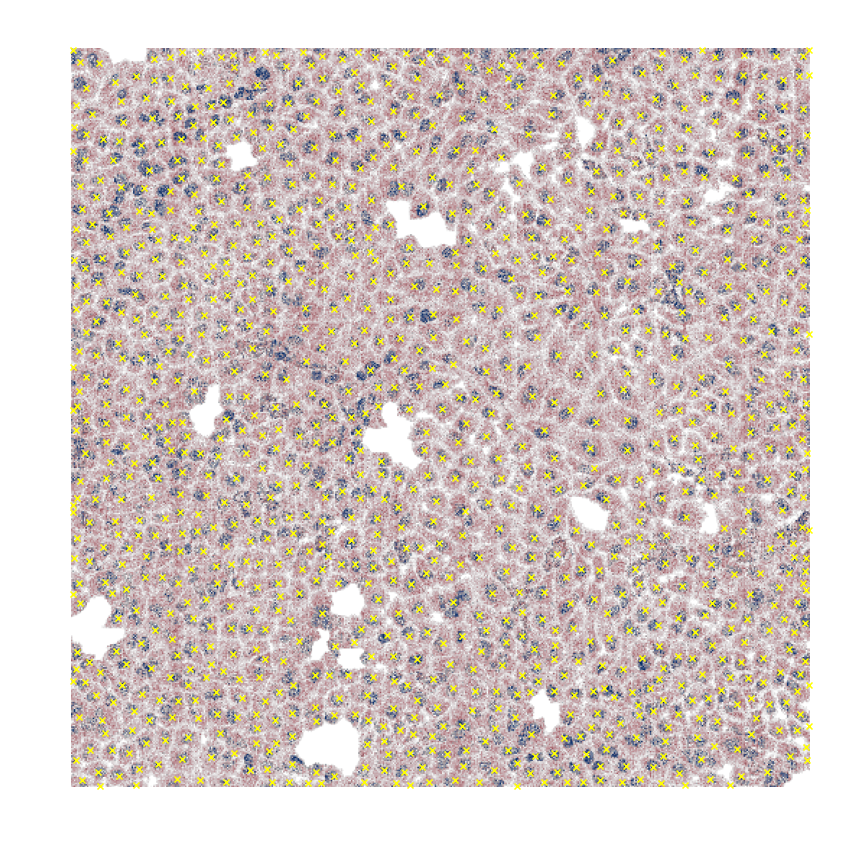

In [30]:
figsize(15, 15)

plt.imshow(final_img, interpolation='hermite');
plt.imshow(tmp_img, interpolation='hermite')

plt.scatter(yy_img, xx_img, marker='x', c='yellow');
plt.axis('off');

Make cell level expression

In [31]:
exp_mat = \
middle.groupby(['cellID', 'name']) \
    .count() \
    .iloc[:, 0] \
    .unstack() \
    .replace(np.nan, 0.0)

In [32]:
exp_mat = exp_mat.T[exp_mat.sum(0) >= 3].T

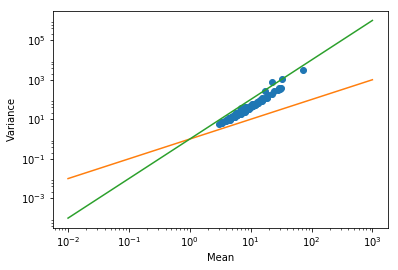

In [33]:
figsize(6, 4)
plt.loglog()
plt.scatter(exp_mat.mean(), exp_mat.var());
xy = [1e-2, 1e3]
plt.plot(xy, xy, c='C1');
plt.plot(xy, np.square(xy), c='C2');
plt.xlabel('Mean')
plt.ylabel('Variance');

In [23]:
big.columns

Index(['barcode', 'barcode_id', 'abs_X', 'abs_Y', 'cellID', 'name'], dtype='object')

In [24]:
big_exp_mat = \
big.groupby(['cellID', 'barcode']) \
    .count() \
    .iloc[:, 0] \
    .unstack() \
    .replace(np.nan, 0.0)

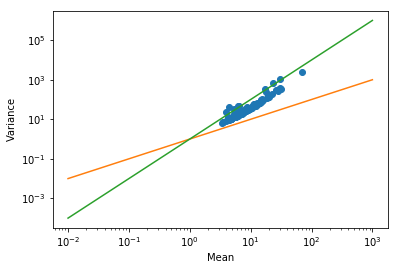

In [25]:
figsize(6, 4)
plt.loglog()
plt.scatter(big_exp_mat.mean(), big_exp_mat.var());
xy = [1e-2, 1e3]
plt.plot(xy, xy, c='C1');
plt.plot(xy, np.square(xy), c='C2');
plt.xlabel('Mean')
plt.ylabel('Variance');

In [26]:
big_sample_info.shape

(39523, 2)

In [27]:
big_exp_mat.shape

(38594, 140)

In [28]:
big_sample_info = big_sample_info.loc[big_exp_mat.index]

In [29]:
big_sample_info.shape

(38594, 2)

In [35]:
big_sample_info.head()

,nucleusArea,cytoplasmArea
cellID,,
3,171.142433,602.671306
4,178.440313,714.667524
5,194.657823,215.740587
6,307.608013,1159.027309
7,196.374972,960.410506


In [36]:
big_sample_coord = \
big.groupby(['cellID']) \
    .mean()[['abs_X', 'abs_Y']]

In [41]:
big_sample_info = pd.concat((big_sample_info, big_sample_coord), 1)

In [42]:
big_sample_info['total_count'] = big_exp_mat.sum(1)

In [48]:
gene_names = big.groupby('barcode').first()[['name']]

In [ ]:
gene_names.set_index()

In [49]:
import anndata

In [81]:
adata = anndata.AnnData(big_exp_mat.values, var=gene_names.set_index('name'), obs=big_sample_info)

In [82]:
adata

AnnData object with n_obs × n_vars = 38594 × 140 
    obs: 'nucleusArea', 'cytoplasmArea', 'abs_X', 'abs_Y', 'total_count'

In [83]:
adata.write('C:/Users/vale/Desktop/MERFISH_140_rep6.h5ad')

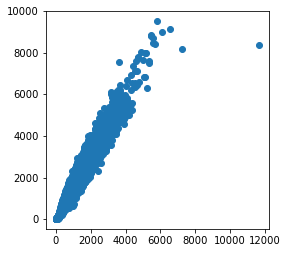

In [41]:
figsize(4, 4)
plt.scatter(big_sample_info.cytoplasmArea, big_sample_info.total_count);

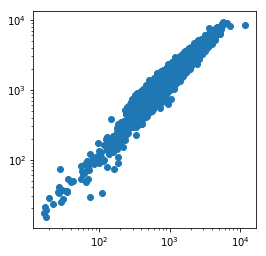

In [42]:
plt.loglog()
figsize(4, 4)
plt.scatter(big_sample_info.cytoplasmArea, big_sample_info.total_count);

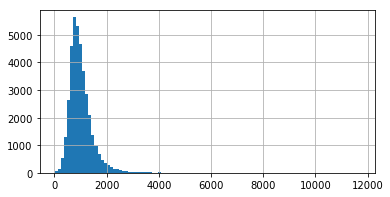

In [43]:
figsize(6, 3)
big_sample_info.cytoplasmArea.hist(bins=100);

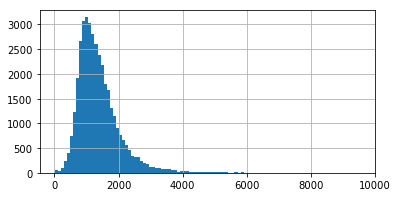

In [44]:
figsize(6, 3)
big_sample_info.total_count.hist(bins=100);

In [45]:
sample_info['total_count'] = exp_mat.sum(1)

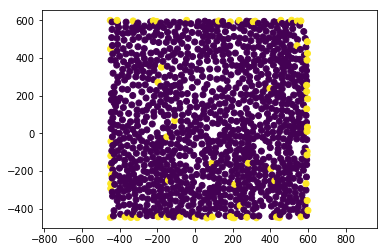

In [46]:
figsize(6, 4)
plt.scatter(sample_info.abs_X, sample_info.abs_Y, c=exp_mat['MALAT1'] < 20)
plt.axis('equal');

In [47]:
exp_mat = exp_mat.loc[~(exp_mat['MALAT1'] < 20)]

In [48]:
sample_info = sample_info.loc[exp_mat.index]

In [49]:
sample_info.total_count.min()

193.0

In [50]:
sample_info.head().T

cellID,16345,16347,16348,16349,16351
abs_X,-438.999143,-437.428582,-432.656618,-429.781788,-412.916125
abs_Y,-312.475845,-334.316858,-438.886660,-411.289794,-358.068636
nucleusArea,193.036072,214.738917,276.365457,292.249077,179.632777
cytoplasmArea,1040.400991,472.263443,1083.329695,1597.377076,887.384010
total_count,828.000000,557.000000,961.000000,1745.000000,1151.000000


In [51]:
exp_mat.to_csv('data/rep6/middle_exp_mat.csv')

In [52]:
sample_info.to_csv('data/rep6/middle_sample_info.csv')

In [56]:
big.abs_X.min(), big.abs_X.max()

(-2600.0, 2600.0)

In [57]:
big.abs_Y.min(), big.abs_Y.max()

(-4103.0, 4103.0)

In [60]:
2 * 2.6

5.2

In [61]:
2 * 4.1

8.2

In [65]:
middle.abs_X.max() - middle.abs_X.min()

1049.98

In [66]:
middle.abs_Y.max() - middle.abs_Y.min()

1049.98

In [68]:
sample_info.shape

(1056, 5)